
# Exploratory Data Analysis (EDA)
## Teen Mental Health Dataset

### Project Objective
The objective of this analysis is to explore the Teen Mental Health dataset, understand its characteristics, identify patterns and relationships between variables, and extract meaningful insights before building machine learning models.


In [2]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the cleaned dataset
df = pd.read_csv("Teen_Mental_Health_Dataset_Cleaned.csv")

# Display dataset dimensions
print("Dataset shape:", df.shape)

# Display the first five rows
display(df.head())


Dataset shape: (1191, 13)


,age,gender,daily_social_media_hours,platform_usage,sleep_hours,screen_time_before_sleep,academic_performance,physical_activity,social_interaction_level,stress_level,anxiety_level,addiction_level,depression_label
0,14,male,7.9,Instagram,7.4,2.9,3.01,1.5,low,2,2,1,0
1,19,female,1.9,TikTok,8.0,2.9,3.22,0.8,high,8,1,10,0
2,17,female,1.3,Instagram,7.6,0.5,3.92,0.0,high,2,4,2,0
3,15,male,7.4,TikTok,6.9,1.6,3.48,0.8,medium,1,7,9,0
4,15,female,4.7,Both,4.9,3.0,2.37,1.4,medium,3,5,2,0


In [3]:

print("COLUMN NAMES AND DATA TYPES")
display(df.dtypes)

print("\nMISSING VALUES")
display(df.isnull().sum())

print("\nDUPLICATE ROWS")
print("Number of duplicate rows:", df.duplicated().sum())

print("\nDESCRIPTIVE STATISTICS")
display(df.describe())


COLUMN NAMES AND DATA TYPES


age                           int64
gender                       object
daily_social_media_hours    float64
platform_usage               object
sleep_hours                 float64
screen_time_before_sleep    float64
academic_performance        float64
physical_activity           float64
social_interaction_level     object
stress_level                  int64
anxiety_level                 int64
addiction_level               int64
depression_label              int64
dtype: object


MISSING VALUES


age                         0
gender                      0
daily_social_media_hours    0
platform_usage              0
sleep_hours                 0
screen_time_before_sleep    0
academic_performance        0
physical_activity           0
social_interaction_level    0
stress_level                0
anxiety_level               0
addiction_level             0
depression_label            0
dtype: int64


DUPLICATE ROWS
Number of duplicate rows: 0

DESCRIPTIVE STATISTICS


,age,daily_social_media_hours,sleep_hours,screen_time_before_sleep,academic_performance,physical_activity,stress_level,anxiety_level,addiction_level,depression_label
count,1191.000000,1191.000000,1191.000000,1191.000000,1191.000000,1191.000000,1191.000000,1191.000000,1191.000000,1191.000000
mean,15.926113,4.536860,6.447943,1.740134,2.990151,1.016121,5.460118,5.636440,5.564232,0.026029
std,2.021211,2.031242,1.415174,0.716716,0.569223,0.582598,2.902311,2.859391,2.834190,0.159287
min,13.000000,1.000000,4.000000,0.500000,2.000000,0.000000,1.000000,1.000000,1.000000,0.000000
25%,14.000000,2.750000,5.200000,1.100000,2.510000,0.500000,3.000000,3.000000,3.000000,0.000000
50%,16.000000,4.500000,6.500000,1.700000,2.980000,1.000000,5.000000,6.000000,6.000000,0.000000
75%,18.000000,6.300000,7.600000,2.400000,3.470000,1.500000,8.000000,8.000000,8.000000,0.000000
max,19.000000,8.000000,9.000000,3.000000,4.000000,2.000000,10.000000,10.000000,10.000000,1.000000


Depression Label Counts:


depression_label
0    1160
1      31
Name: count, dtype: int64


Percentages:


depression_label
0    97.4
1     2.6
Name: proportion, dtype: float64

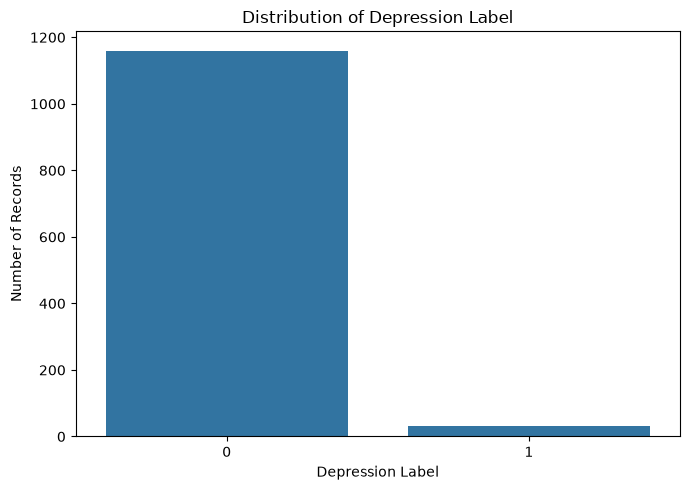

In [4]:

# Depression Label Distribution

label_counts = df["depression_label"].value_counts().sort_index()

print("Depression Label Counts:")
display(label_counts)

print("\nPercentages:")
display((df["depression_label"].value_counts(normalize=True)
         .sort_index() * 100).round(2))

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="depression_label")
plt.title("Distribution of Depression Label")
plt.xlabel("Depression Label")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()


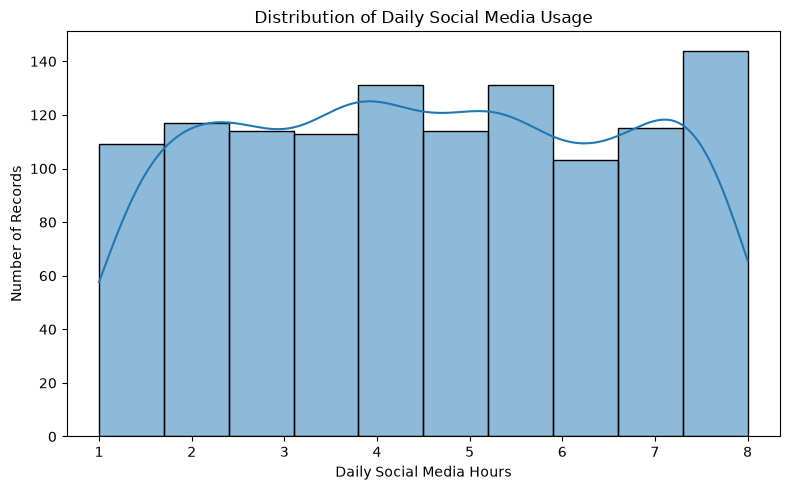

In [5]:

# Daily Social Media Usage Distribution

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="daily_social_media_hours",
             bins=10, kde=True)

plt.title("Distribution of Daily Social Media Usage")
plt.xlabel("Daily Social Media Hours")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()


Average Values by Depression Label:


,sleep_hours,daily_social_media_hours,stress_level,anxiety_level
depression_label,,,,
0,6.49,4.48,5.38,5.56
1,4.78,6.72,8.48,8.61


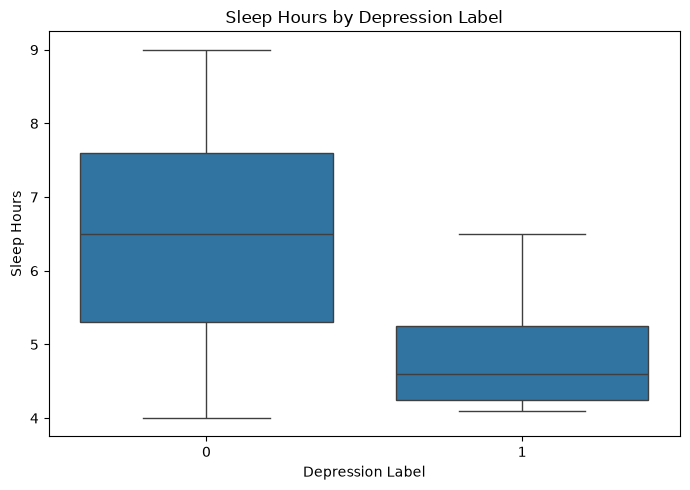

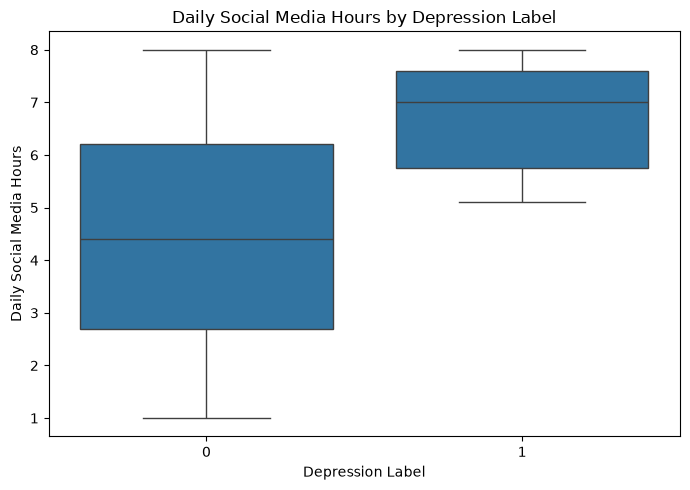

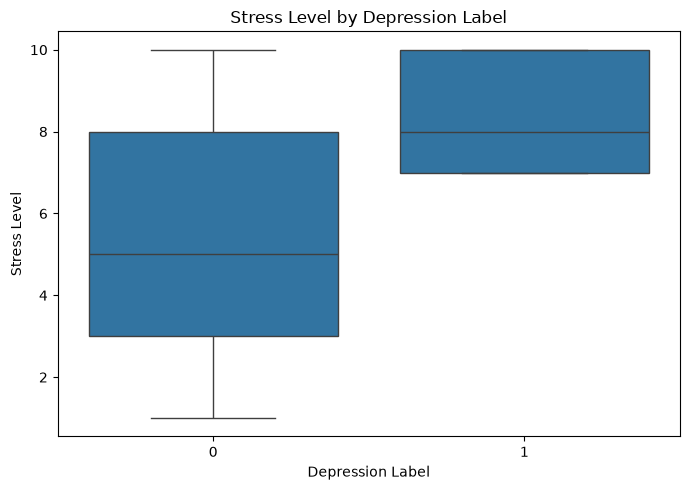

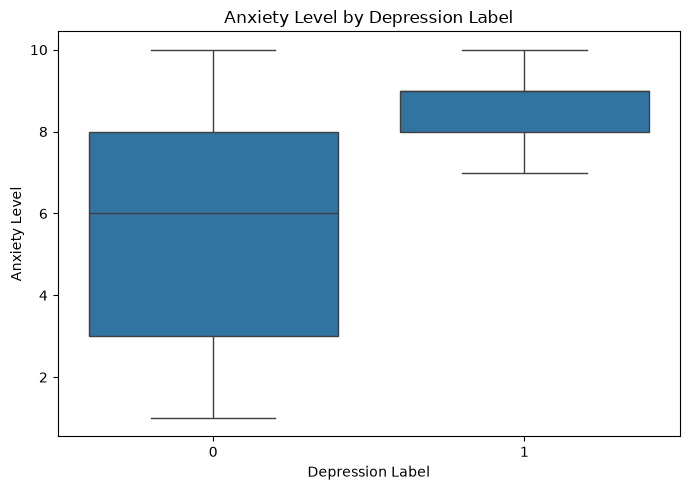

In [7]:

# Compare Numerical Features by Depression Label

features_to_compare = [
    "sleep_hours",
    "daily_social_media_hours",
    "stress_level",
    "anxiety_level"
]

print("Average Values by Depression Label:")
display(
    df.groupby("depression_label")[features_to_compare]
    .mean()
    .round(2)
)

for column in features_to_compare:
    plt.figure(figsize=(7, 5))
    sns.boxplot(data=df, x="depression_label", y=column)
    plt.title(f"{column.replace('_', ' ').title()} by Depression Label")
    plt.xlabel("Depression Label")
    plt.ylabel(column.replace("_", " ").title())
    plt.tight_layout()
    plt.show()


## Key Findings and Business Insights

### 2. Depression Label Distribution
The dataset contains 1,160 records with label 0 (97.4%) and 31 records with label 1 (2.6%). This indicates a substantial class imbalance that should be considered during future model evaluation.

### 3. Sleep Duration
Records with label 1 had an average sleep duration of 4.78 hours, compared with 6.49 hours for records with label 0. This difference suggests an association between shorter sleep duration and the target label.

### 4. Daily Social Media Usage
Records with label 1 had average daily social media usage of 6.72 hours, compared with 4.48 hours for records with label 0. This difference suggests an association between higher daily social media usage and the target label.

### 5. Comparison of Target Groups
Comparing the average values of selected features revealed differences in sleep duration and daily social media usage between the two target groups. These differences may be useful for further investigation during the modeling stage.

